# Day 8 — Module 3.2: Non-Parametric Rank Correlation (Spearman's $\rho$ & Kendall's $\tau$)
> **Programme:** C-DAC PGCP-AI (Post Graduate Certificate Programme in AI)  
> **Course:** Data Analytics  
> **Author:** abs6187 (`23f2000876@ds.study.iitm.ac.in`)  
> **Date:** October 1, 2026  

---

### 🎯 Learning Objectives:
1. **Non-Parametric Foundations:** Understand why rank-based correlation overcomes Pearson's strict linearity and normality assumptions.
2. **Spearman's Rank Correlation ($\rho$ / $r_s$):** Formula, rank differencing mechanics, and monotonic curve evaluation ($Y = e^X$).
3. **Kendall's Rank Correlation (Kendall's Tau $\tau$):** Concordant vs. discordant pairs, probabilistic interpretation, and Tau-a vs. Tau-b.
4. **Step-by-Step Hand Numerical Example:** Complete manual breakdown showing how $\rho = 0.9000$ and $\tau = 0.8000$ are calculated step-by-step from raw data.
5. **Concordance Ladder Visualization:** Visualizing rank transitions and crossing discordant pairs via Parallel Coordinates.
6. **Outlier Stress Test:** Proving mathematically and empirically why rank metrics remain stable when a massive leverage outlier destroys Pearson's $r$.
7. **Multi-Tier Python Implementations:** Pure Python (from scratch), NumPy, Pandas, and SciPy Stats (`spearmanr`, `kendalltau`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats

# Apply clean visual styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 100
print("Setup completed successfully: NumPy, Pandas, Matplotlib, and SciPy ready.")


Setup completed successfully: NumPy, Pandas, Matplotlib, and SciPy ready.


## 1. Theoretical Foundations: Spearman's $\rho$ vs. Kendall's $\tau$

### A. Why Rank Correlation?
Pearson's correlation coefficient ($r$) evaluates the strength of a **linear** association. However, real-world data frequently exhibits:
1. **Non-linear monotonic patterns:** Growth curves (exponential, logarithmic, power laws) where variables strictly increase together, but not at a constant rate.
2. **Ordinal data:** Rankings, feedback surveys (Likert scales 1–5), or competitive standings where arithmetic distances between points are meaningless.
3. **Extreme outliers:** Heavy-tailed financial, sensor, or cyber-fraud distributions that heavily distort sample means and standard deviations.

**Rank Correlation** solves this by converting continuous or ordinal values into simple ordinal ranks ($1, 2, \dots, n$), stripping away arbitrary scaling and extreme distance leverage.

---

### B. Spearman's Rank Correlation Coefficient ($\rho$)
- **What it is:** Pearson's correlation calculated directly on the **assigned ranks** of $X$ and $Y$.
- **Mathematical Formula (No ties):**
  $$\rho = 1 - \frac{6 \sum_{i=1}^n d_i^2}{n(n^2 - 1)}$$
  *Where:*
  * $R(x_i)$ is the rank of observation $x_i$, and $R(y_i)$ is the rank of observation $y_i$.
  * $d_i = R(x_i) - R(y_i)$ is the rank difference for individual $i$.
  * $n$ is the sample size.
- **Value Range:** $[-1.0, +1.0]$.
  * $\rho = +1.0$: Perfect monotonic positive relationship ($X$ increases $\implies Y$ always increases).
  * $\rho = -1.0$: Perfect monotonic negative relationship ($X$ increases $\implies Y$ always decreases).
  * $\rho = 0.0$: No monotonic trend.

---

### C. Kendall's Rank Correlation Coefficient (Kendall's Tau $\tau$)
- **What it is:** A non-parametric measure based on the relative ordering of all distinct **pairs** of observations.
- **Pairwise Classification:** For any two observations $(x_i, y_i)$ and $(x_j, y_j)$ with $i < j$:
  * **Concordant Pair ($C$):** The order of both variables is identical:
    $$(x_i < x_j \text{ and } y_i < y_j) \quad \text{OR} \quad (x_i > x_j \text{ and } y_i > y_j) \iff (x_i - x_j)(y_i - y_j) > 0$$
  * **Discordant Pair ($D$):** The order of variables is reversed (one goes up, the other goes down):
    $$(x_i < x_j \text{ and } y_i > y_j) \quad \text{OR} \quad (x_i > x_j \text{ and } y_i < y_j) \iff (x_i - x_j)(y_i - y_j) < 0$$
  * **Tied Pair:** Values are identical in $X$ or $Y$: $(x_i - x_j)(y_i - y_j) = 0$.

- **Total Number of Pairs:** For $n$ observations, there are $\binom{n}{2} = \frac{n(n - 1)}{2}$ distinct pairs.
- **Formula (Kendall's Tau-a, no ties):**
  $$\tau = \frac{C - D}{\frac{1}{2} n (n - 1)} = \frac{C - D}{C + D}$$
- **Probabilistic Meaning:**
  $$\tau = P(\text{concordance}) - P(\text{discordance})$$
  *Example:* $\tau = +0.80$ means that if you pick any two random students, there is an 80% higher probability that the student who studied more also scored higher than vice versa.

## 2. Step-by-Step Hand Numerical Example

### Problem Scenario:
A cohort of $n = 5$ students was evaluated on **Coding Aptitude Test ($X$)** and **Machine Learning Project Score ($Y$)**:

| Student | Aptitude ($X$) | ML Score ($Y$) |
| :---: | :---: | :---: |
| **A** | 12 | 45 |
| **B** | 15 | 60 |
| **C** | 18 | 55 |
| **D** | 22 | 80 |
| **E** | 25 | 90 |

---

### Part A: Calculating Spearman's $\rho$ by Hand
1. **Assign Ranks:**
   * $X = [12, 15, 18, 22, 25]$ (already ascending) $\implies R(X) = [1, 2, 3, 4, 5]$.
   * $Y = [45, 60, 55, 80, 90]$. In ascending order: $45 < 55 < 60 < 80 < 90$.
     * $45 \to \text{Rank } 1$
     * $55 \to \text{Rank } 2$ (Student C)
     * $60 \to \text{Rank } 3$ (Student B)
     * $80 \to \text{Rank } 4$
     * $90 \to \text{Rank } 5$
     * Therefore: $R(Y) = [1, 3, 2, 4, 5]$.

2. **Calculate Rank Differences ($d_i$) and Squared Differences ($d_i^2$):**

| Student | $X$ | $Y$ | $R(X)$ | $R(Y)$ | $d_i = R(X) - R(Y)$ | $d_i^2$ |
| :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **A** | 12 | 45 | 1 | 1 | $1 - 1 = 0$ | $0$ |
| **B** | 15 | 60 | 2 | 3 | $2 - 3 = -1$ | $1$ |
| **C** | 18 | 55 | 3 | 2 | $3 - 2 = +1$ | $1$ |
| **D** | 22 | 80 | 4 | 4 | $4 - 4 = 0$ | $0$ |
| **E** | 25 | 90 | 5 | 5 | $5 - 5 = 0$ | $0$ |
| **Total ($\Sigma$)** | — | — | — | — | **0** | **2** |

3. **Substitute into Spearman's Formula:**
   $$\rho = 1 - \frac{6 \sum d_i^2}{n(n^2 - 1)} = 1 - \frac{6 \times 2}{5(5^2 - 1)} = 1 - \frac{12}{5 \times 24} = 1 - \frac{12}{120} = 1 - 0.10 = \mathbf{+0.9000}$$

---

### Part B: Calculating Kendall's $\tau$ by Hand
1. **Enumerate All $\binom{5}{2} = \frac{5 \times 4}{2} = 10$ Pairs:**
   Since $X$ is sorted ascending ($X_i < X_j$ for all $i < j$), pair $(i, j)$ is **Concordant** if $Y_i < Y_j$, and **Discordant** if $Y_i > Y_j$:

| Pair $(i, j)$ | Student Pair | $X$-comparison ($x_j - x_i$) | $Y$-comparison ($y_j - y_i$) | Product $(x_j - x_i)(y_j - y_i)$ | Classification |
| :---: | :---: | :---: | :---: | :---: | :---: |
| 1 | **(A, B)** | $15 - 12 = +3 > 0$ | $60 - 45 = +15 > 0$ | $+45 > 0$ | **Concordant** |
| 2 | **(A, C)** | $18 - 12 = +6 > 0$ | $55 - 45 = +10 > 0$ | $+60 > 0$ | **Concordant** |
| 3 | **(A, D)** | $22 - 12 = +10 > 0$ | $80 - 45 = +35 > 0$ | $+350 > 0$ | **Concordant** |
| 4 | **(A, E)** | $25 - 12 = +13 > 0$ | $90 - 45 = +45 > 0$ | $+585 > 0$ | **Concordant** |
| 5 | **(B, C)** | $18 - 15 = +3 > 0$ | $55 - 60 = -5 < 0$ | $\mathbf{-15 < 0}$ | **DISCORDANT (Inversion)** |
| 6 | **(B, D)** | $22 - 15 = +7 > 0$ | $80 - 60 = +20 > 0$ | $+140 > 0$ | **Concordant** |
| 7 | **(B, E)** | $25 - 15 = +10 > 0$ | $90 - 60 = +30 > 0$ | $+300 > 0$ | **Concordant** |
| 8 | **(C, D)** | $22 - 18 = +4 > 0$ | $80 - 55 = +25 > 0$ | $+100 > 0$ | **Concordant** |
| 9 | **(C, E)** | $25 - 18 = +7 > 0$ | $90 - 55 = +35 > 0$ | $+245 > 0$ | **Concordant** |
| 10 | **(D, E)** | $25 - 22 = +3 > 0$ | $90 - 80 = +10 > 0$ | $+30 > 0$ | **Concordant** |

2. **Tally Counts:**
   * **Concordant Pairs ($C$):** $9$
   * **Discordant Pairs ($D$):** $1$ (Only Student B scored higher than C despite having lower aptitude)
   * **Total Pairs ($C + D$):** $10$

3. **Substitute into Kendall's Formula:**
   $$\tau = \frac{C - D}{\frac{1}{2} n (n - 1)} = \frac{9 - 1}{10} = \frac{8}{10} = \mathbf{+0.8000}$$
> **Key Insight:** Spearman's $\rho = 0.9000$ and Kendall's $\tau = 0.8000$. Kendall's $\tau$ is generally slightly lower in magnitude than Spearman's $\rho$ for the same data because they operate on different geometric principles (squared distance in ranks vs. pair concordances), but both identify strong positive monotonic alignment.

In [4]:
# ==============================================================================
# PURE PYTHON IMPLEMENTATION & VERIFICATION AUDIT
# ==============================================================================
students = ['Student A', 'Student B', 'Student C', 'Student D', 'Student E']
x = [12, 15, 18, 22, 25]
y = [45, 60, 55, 80, 90]
n = len(x)

# --- 1. PURE PYTHON SPEARMAN RHO ---
def get_ranks(arr):
    """Assigns 1-based ranks (handling unique elements)."""
    sorted_indices = sorted(range(len(arr)), key=lambda k: arr[k])
    ranks = [0] * len(arr)
    for rank, idx in enumerate(sorted_indices, 1):
        ranks[idx] = rank
    return ranks

rank_x = get_ranks(x)
rank_y = get_ranks(y)
d = [rx - ry for rx, ry in zip(rank_x, rank_y)]
d_sq = [diff ** 2 for diff in d]
sum_d_sq = sum(d_sq)
rho_manual = 1.0 - (6.0 * sum_d_sq) / (n * (n**2 - 1))

# --- 2. PURE PYTHON KENDALL TAU ---
concordant_pairs = []
discordant_pairs = []
for i in range(n):
    for j in range(i + 1, n):
        dx = x[j] - x[i]
        dy = y[j] - y[i]
        prod = dx * dy
        pair_label = f"{students[i]} vs {students[j]}"
        if prod > 0:
            concordant_pairs.append((pair_label, dx, dy, prod, "Concordant"))
        elif prod < 0:
            discordant_pairs.append((pair_label, dx, dy, prod, "Discordant"))

C = len(concordant_pairs)
D = len(discordant_pairs)
total_pairs = n * (n - 1) // 2
tau_manual = (C - D) / total_pairs

# --- 3. FORMAT TABULAR AUDIT (PANDAS) ---
df_spearman = pd.DataFrame({
    'Student': students,
    'X (Aptitude)': x,
    'Y (Score)': y,
    'Rank(X)': rank_x,
    'Rank(Y)': rank_y,
    'd = Rx - Ry': d,
    'd²': d_sq
})

print("=" * 75)
print("         STEP-BY-STEP SPEARMAN RANK AUDIT TABLE (HAND CALCULATION)        ")
print("=" * 75)
print(df_spearman.to_string(index=False))
print(f"\nSum of squared rank differences Σ d² : {sum_d_sq}")
print(f"Spearman Rho (Manual)               : {rho_manual:.4f}")
print("=" * 75)

# --- 4. VERIFICATION AGAINST SCIPY & PANDAS ---
rho_scipy, p_rho = stats.spearmanr(x, y)
tau_scipy, p_tau = stats.kendalltau(x, y)

df_test = pd.DataFrame({'X': x, 'Y': y})
rho_pandas = df_test['X'].corr(df_test['Y'], method='spearman')
tau_pandas = df_test['X'].corr(df_test['Y'], method='kendall')

print("\n--- DUAL VERIFICATION AUDIT (Manual vs SciPy vs Pandas) ---")
print(f"Spearman's Rho : Manual = {rho_manual:.4f} | SciPy = {rho_scipy:.4f} | Pandas = {rho_pandas:.4f} (Match: {np.isclose(rho_manual, rho_scipy)})")
print(f"Kendall's Tau  : Manual = {tau_manual:.4f} | SciPy = {tau_scipy:.4f} | Pandas = {tau_pandas:.4f} (Match: {np.isclose(tau_manual, tau_scipy)})")
print(f"Pairwise Breakdown: Concordant (C) = {C}, Discordant (D) = {D}, Total = {total_pairs}")
print("=" * 75)


         STEP-BY-STEP SPEARMAN RANK AUDIT TABLE (HAND CALCULATION)        
  Student  X (Aptitude)  Y (Score)  Rank(X)  Rank(Y)  d = Rx - Ry  d²
Student A            12         45        1        1            0   0
Student B            15         60        2        3           -1   1
Student C            18         55        3        2            1   1
Student D            22         80        4        4            0   0
Student E            25         90        5        5            0   0

Sum of squared rank differences Σ d² : 2
Spearman Rho (Manual)               : 0.9000

--- DUAL VERIFICATION AUDIT (Manual vs SciPy vs Pandas) ---
Spearman's Rho : Manual = 0.9000 | SciPy = 0.9000 | Pandas = 0.9000 (Match: True)
Kendall's Tau  : Manual = 0.8000 | SciPy = 0.8000 | Pandas = 0.8000 (Match: True)
Pairwise Breakdown: Concordant (C) = 9, Discordant (D) = 1, Total = 10


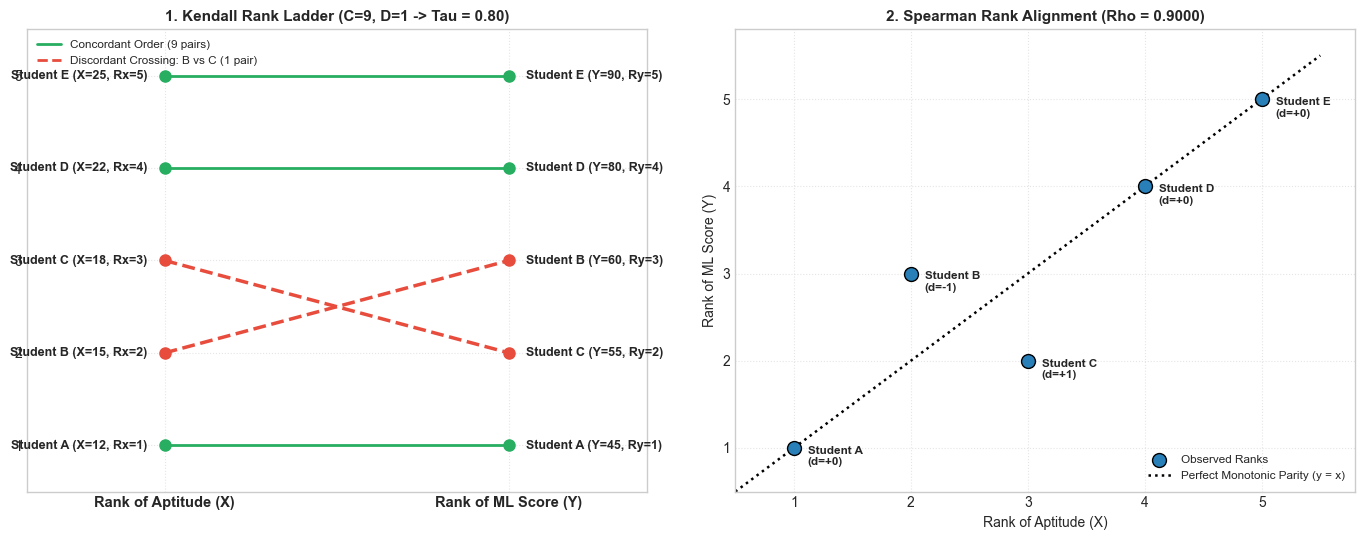

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# ------------------------------------------------------------------------------
# Subplot 1: Kendall Concordance Ladder Chart (Parallel Coordinates)
# ------------------------------------------------------------------------------
for i in range(n):
    is_crossing = (students[i] in ['Student B', 'Student C'])
    color = '#e74c3c' if is_crossing else '#27ae60'
    linestyle = '--' if is_crossing else '-'
    linewidth = 2.5 if is_crossing else 2.0
    
    ax1.plot([0, 1], [rank_x[i], rank_y[i]], color=color, linestyle=linestyle, 
             linewidth=linewidth, marker='o', markersize=8, zorder=5)
    
    ax1.text(-0.05, rank_x[i], f"{students[i]} (X={x[i]}, Rx={rank_x[i]})", 
             ha='right', va='center', fontweight='bold', fontsize=9)
    ax1.text(1.05, rank_y[i], f"{students[i]} (Y={y[i]}, Ry={rank_y[i]})", 
             ha='left', va='center', fontweight='bold', fontsize=9)

ax1.plot([], [], color='#27ae60', linestyle='-', linewidth=2, label='Concordant Order (9 pairs)')
ax1.plot([], [], color='#e74c3c', linestyle='--', linewidth=2, label='Discordant Crossing: B vs C (1 pair)')
ax1.set_xlim(-0.4, 1.4)
ax1.set_ylim(0.5, 5.5)
ax1.set_xticks([0, 1])
ax1.set_xticklabels(['Rank of Aptitude (X)', 'Rank of ML Score (Y)'], fontweight='bold', fontsize=10.5)
ax1.set_yticks(range(1, 6))
ax1.set_title(f'1. Kendall Rank Ladder (C={C}, D={D} -> Tau = {tau_manual:.2f})', fontweight='bold', fontsize=11)
ax1.legend(loc='upper left', fontsize=8.5)
ax1.grid(True, linestyle=':', alpha=0.5)

# ------------------------------------------------------------------------------
# Subplot 2: Rank Scatter Parity (Rx vs Ry)
# ------------------------------------------------------------------------------
ax2.scatter(rank_x, rank_y, color='#2980b9', s=100, zorder=5, edgecolor='black', label='Observed Ranks')
ax2.plot([0.5, 5.5], [0.5, 5.5], color='black', linestyle=':', linewidth=1.8, label='Perfect Monotonic Parity (y = x)')

for i in range(n):
    d_val = rank_x[i] - rank_y[i]
    ax2.annotate(f"{students[i]}\n(d={d_val:+d})", (rank_x[i] + 0.12, rank_y[i] - 0.2), 
                 fontsize=8.5, fontweight='bold')

ax2.set_xlim(0.5, 5.8)
ax2.set_ylim(0.5, 5.8)
ax2.set_xticks(range(1, 6))
ax2.set_yticks(range(1, 6))
ax2.set_xlabel('Rank of Aptitude (X)', fontsize=10)
ax2.set_ylabel('Rank of ML Score (Y)', fontsize=10)
ax2.set_title(f'2. Spearman Rank Alignment (Rho = {rho_manual:.4f})', fontweight='bold', fontsize=11)
ax2.legend(loc='lower right', fontsize=8.5)
ax2.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()


## 3. Robustness Stress Test: Extreme Outlier Leverage

The primary reason non-parametric rank metrics are mandatory in production data pipelines is their **resistance to extreme leverage outliers**.

- **Pearson Correlation ($r$):** Calculates distance-based squared deviations $(x_i - \bar{x})(y_i - \bar{y})$. A single corrupted data point (e.g. sensor malfunction, rogue financial transaction, misplaced decimal point) has **infinite leverage** and can flip a correlation from $+0.95$ to $0.00$ or even negative!
- **Spearman ($\rho$) & Kendall ($\tau$):** An outlier, no matter how astronomically huge or negative, can only take the highest rank ($n$) or lowest rank ($1$). Its leverage is strictly bounded by the rank bounds.

Below we empirically test this by taking a clean linear dataset of $n = 40$ observations and injecting **just one single corrupted point** at $(48, -30)$.

             OUTLIER LEVERAGE STRESS TEST: CLEAN VS. CORRUPTED            
Metric                  | Clean Data (n=40) | 1 Outlier Injected (n=41) | Delta (Loss)
---------------------------------------------------------------------------
Pearson Correlation (r) |            0.9874 |                    0.7026 |      -0.2848 (COLLAPSED!)
Spearman Rank (rho)     |            0.9893 |                    0.8606 |      -0.1287 (ROBUST)
Kendall's Tau (tau)     |            0.9231 |                    0.8341 |      -0.0889 (MOST STABLE!)


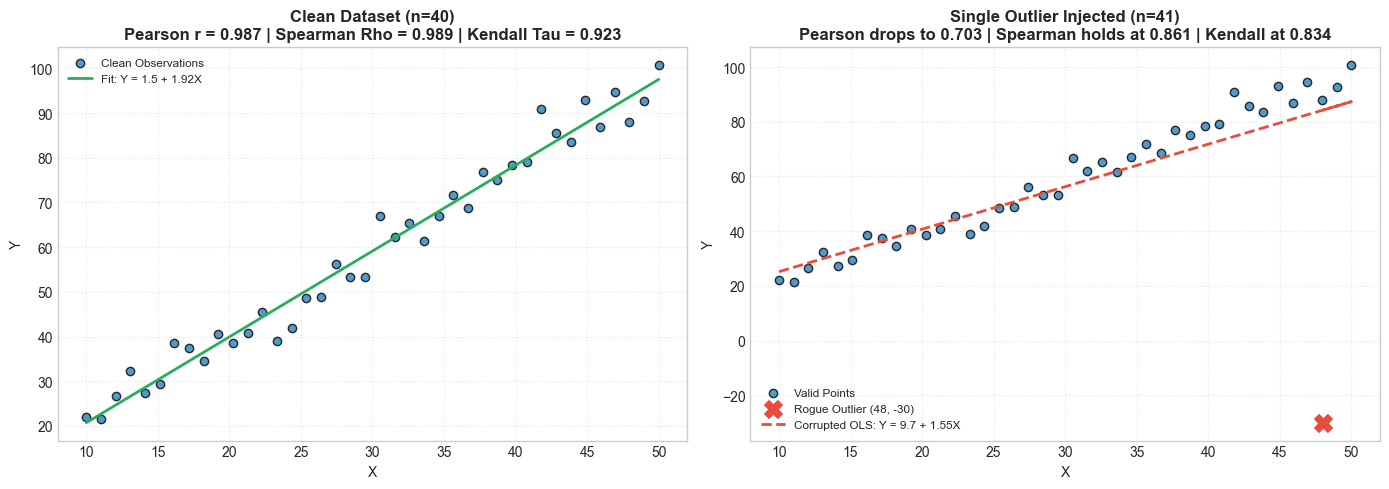

In [7]:
np.random.seed(42)
n_clean = 40
x_clean = np.linspace(10, 50, n_clean)
# True relationship: Y = 2 * X + noise
y_clean = 2.0 * x_clean + np.random.normal(0, 4, n_clean)

# Inject Single Catastrophic Leverage Outlier at (48, -30)
x_corrupted = np.append(x_clean, [48.0])
y_corrupted = np.append(y_clean, [-30.0])

# Compute Metrics Before vs After
r_clean, _ = stats.pearsonr(x_clean, y_clean)
rho_clean, _ = stats.spearmanr(x_clean, y_clean)
tau_clean, _ = stats.kendalltau(x_clean, y_clean)

r_corrupt, _ = stats.pearsonr(x_corrupted, y_corrupted)
rho_corrupt, _ = stats.spearmanr(x_corrupted, y_corrupted)
tau_corrupt, _ = stats.kendalltau(x_corrupted, y_corrupted)

print("=" * 75)
print("             OUTLIER LEVERAGE STRESS TEST: CLEAN VS. CORRUPTED            ")
print("=" * 75)
print(f"Metric                  | Clean Data (n=40) | 1 Outlier Injected (n=41) | Delta (Loss)")
print("-" * 75)
print(f"Pearson Correlation (r) | {r_clean:17.4f} | {r_corrupt:25.4f} | {r_corrupt - r_clean:+12.4f} (COLLAPSED!)")
print(f"Spearman Rank (rho)     | {rho_clean:17.4f} | {rho_corrupt:25.4f} | {rho_corrupt - rho_clean:+12.4f} (ROBUST)")
print(f"Kendall's Tau (tau)     | {tau_clean:17.4f} | {tau_corrupt:25.4f} | {tau_corrupt - tau_clean:+12.4f} (MOST STABLE!)")
print("=" * 75)

# Multi-Panel Plot of Stress Test
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Clean Data
ax1.scatter(x_clean, y_clean, color='#2980b9', alpha=0.8, edgecolor='k', label='Clean Observations')
m_c, b_c = np.polyfit(x_clean, y_clean, 1)
ax1.plot(x_clean, b_c + m_c * x_clean, color='#27ae60', linewidth=2, label=f'Fit: Y = {b_c:.1f} + {m_c:.2f}X')
ax1.set_title(f'Clean Dataset (n=40)\nPearson r = {r_clean:.3f} | Spearman Rho = {rho_clean:.3f} | Kendall Tau = {tau_clean:.3f}', fontweight='bold')
ax1.set_xlabel('X')
ax1.set_ylabel('Y')
ax1.legend(loc='upper left', fontsize=8.5)
ax1.grid(True, linestyle=':', alpha=0.5)

# Plot 2: Corrupted with Single Outlier
ax2.scatter(x_clean, y_clean, color='#2980b9', alpha=0.8, edgecolor='k', label='Valid Points')
ax2.scatter([48.0], [-30.0], color='#e74c3c', s=160, marker='X', zorder=6, label='Rogue Outlier (48, -30)')
m_x, b_x = np.polyfit(x_corrupted, y_corrupted, 1)
ax2.plot(x_corrupted, b_x + m_x * x_corrupted, color='#e74c3c', linestyle='--', linewidth=2, label=f'Corrupted OLS: Y = {b_x:.1f} + {m_x:.2f}X')
ax2.set_title(f'Single Outlier Injected (n=41)\nPearson drops to {r_corrupt:.3f} | Spearman holds at {rho_corrupt:.3f} | Kendall at {tau_corrupt:.3f}', fontweight='bold')
ax2.set_xlabel('X')
ax2.set_ylabel('Y')
ax2.legend(loc='lower left', fontsize=8.5)
ax2.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()


## 4. Handling Tied Observations: Kendall's Tau-b ($\tau_b$)

When duplicate observations exist (e.g. two candidates receiving the same interview score), rank ties occur. Rank ties are handled by assigning the **average (fractional) rank**:
- Example: If two values tie for 2nd and 3rd place, both are assigned rank $\frac{2 + 3}{2} = 2.5$.

In Kendall's correlation, ties are partitioned into:
- $T_X$: Number of pairs tied on variable $X$ only.
- $T_Y$: Number of pairs tied on variable $Y$ only.
- Pairs tied on both $X$ and $Y$ are neutral and excluded.

**Formula for Kendall's Tau-b:**
$$\tau_b = \frac{C - D}{\sqrt{(C + D + T_X)(C + D + T_Y)}}$$
*Note:* SciPy (`stats.kendalltau`) and Pandas (`df.corr(method='kendall')`) default to **Tau-b** by default.

In [9]:
# Demonstration of Tied Rankings with SciPy
x_ties = np.array([1, 2, 2, 4, 5])
y_ties = np.array([2, 3, 3, 5, 5])

print("Tied Ranks Example:")
print("X:", x_ties, "--> Ranks:", stats.rankdata(x_ties))
print("Y:", y_ties, "--> Ranks:", stats.rankdata(y_ties))

tau_b, p_val_b = stats.kendalltau(x_ties, y_ties, variant='b')
rho_tied, p_val_rho = stats.spearmanr(x_ties, y_ties)

print(f"\nKendall's Tau-b (adjusted for ties) : {tau_b:.4f} (p-value: {p_val_b:.4f})")
print(f"Spearman's Rho (adjusted for ties)   : {rho_tied:.4f} (p-value: {p_val_rho:.4f})")


Tied Ranks Example:
X: [1 2 2 4 5] --> Ranks: [1.  2.5 2.5 4.  5. ]
Y: [2 3 3 5 5] --> Ranks: [1.  2.5 2.5 4.5 4.5]

Kendall's Tau-b (adjusted for ties) : 0.9428 (p-value: 0.0317)
Spearman's Rho (adjusted for ties)   : 0.9733 (p-value: 0.0052)


## 5. Master Comparison: Pearson vs. Spearman vs. Kendall's Tau

| Attribute / Metric | Pearson Correlation ($r$) | Spearman Rank ($\rho$) | Kendall's Tau ($\tau$) |
| :--- | :---: | :---: | :---: |
| **Mathematical Target** | Degree of **Linear** association | Degree of **Monotonic** association | Concordance vs. Discordance probability |
| **Data Type Required** | Continuous, normally distributed | Continuous or Ordinal | Continuous or Ordinal |
| **Parametric?** | **Yes** (assumes bivariate normal) | **No** (Non-parametric) | **No** (Non-parametric) |
| **Scale Invariant?** | Yes | Yes | Yes |
| **Outlier Robustness** | **Extremely Poor** (high leverage) | **High** | **Highest** (smallest gross error sensitivity) |
| **Handling of Small $n$** | Unreliable if distribution skewed | Good | **Best** (exact sampling distribution) |
| **Computational Cost** | $O(n)$ | $O(n \log n)$ | $O(n^2)$ naive / $O(n \log n)$ |
| **Interpretation** | % variance explained ($r^2$) | Rank difference squared ($d_i^2$) | $P(\text{agreement}) - P(\text{disagreement})$ |

---

### 💡 Key Viva Questions & Answers
1. **Q:** *Why is Kendall's Tau preferred over Spearman's Rho for small sample sizes?*  
   **A:** Kendall's $\tau$ has a direct probabilistic meaning ($P(\text{concordance}) - P(\text{discordance})$), smaller gross error sensitivity, and its test statistic converges to a standard Gaussian distribution much faster than Spearman's $\rho$ when $n < 30$.

2. **Q:** *If two variables have an exponential relationship $Y = e^X$, what will Pearson, Spearman, and Kendall show?*  
   **A:** Pearson $r$ will be penalized ($r \approx 0.85 - 0.90$) due to non-linear curvature. Spearman $\rho$ and Kendall $\tau$ will both be **$+1.0000$** because the monotonic rank order is $100\%$ preserved.

3. **Q:** *What is the difference between Kendall's Tau-a and Tau-b?*  
   **A:** Tau-a assumes there are no tied observations. Tau-b introduces explicit denominator corrections $\sqrt{(C + D + T_X)(C + D + T_Y)}$ for tied ranks, making it suitable for discrete or ordinal rating scales.